# ML-06 — Signal Audit: Do the Flags Hold?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/begs44/flyrank-ml/blob/main/work/notebooks/w04_signal_audit.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Distributions

*Look before deciding: distributions of your key fields. Note the heavy tails.*

**What the distributions show (n = 30,000 pages):**
- **Traffic is heavily skewed.** Median impressions are 731, but the top 1% have more than 73,000 and the max is 517,715. Clicks: median 1, max 4,178. So I use log scales and buckets, never raw means.
- **CTR has a long tail.** Median 0.1%, but the max is 100%. These are tiny pages where 1 click out of 1 impression makes a huge rate, so CTR is only read on pages with a volume floor.
- **`avg_position = 0` means "no data"** (1,205 rows). I remove these before reading position.
- **`days_since_last_update` is basically two values** (20 and 104 days). This looks like batch updates, not natural ageing.
- **`word_count` is missing for 7,699 rows,** all of them `keyword article` (28% of that type). I show missing as its own group instead of filling it with 0.

Rows: 30,000 | base decline rate: 0.542

                          count    mean     50%      90%      99%       max
impressions_90d         30000.0  5200.4   731.0  12136.4  73505.8  517715.0
clicks_90d              30000.0    16.1     1.0     32.0    253.0    4178.0
ctr                     30000.0     0.5     0.1      0.6      8.3     100.0
avg_position            30000.0    16.3    10.8     36.8     69.9     245.0
content_age_days        30000.0   256.2   236.0    463.0    537.0     564.0
days_since_last_update  30000.0    46.1    20.0    104.0    106.0     373.0
word_count              22301.0  3107.8  2877.0   5327.0   7292.0    9546.0 

avg_position == 0 (no data): 1,205 rows
word_count missing: 7,699 rows — by content_type:
content_type
comparison article    0.00
feedly article        0.00
keyword article       0.28 



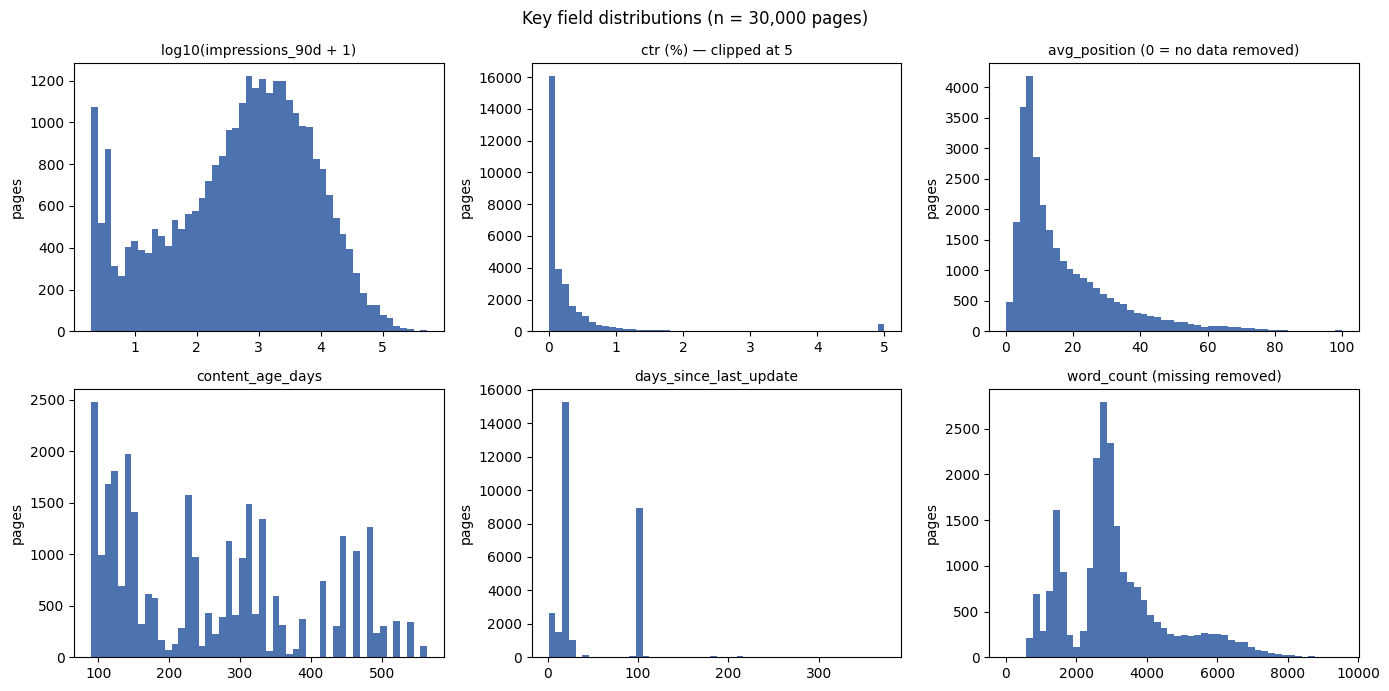

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/begs44/flyrank-ml/main/data/raw/content_refresh_anonymized.csv"
df = pd.read_csv(url)
df["target_decay"] = (df["trend_direction"] == "down").astype(int)   # used ONLY to check signals
base = df["target_decay"].mean()
print(f"Rows: {len(df):,} | base decline rate: {base:.3f}\n")

key = ["impressions_90d", "clicks_90d", "ctr", "avg_position",
       "content_age_days", "days_since_last_update", "word_count"]
summary = df[key].describe(percentiles=[0.5, 0.9, 0.99]).T[["count", "mean", "50%", "90%", "99%", "max"]]
print(summary.round(1).to_string(), "\n")
print(f"avg_position == 0 (no data): {(df['avg_position'] == 0).sum():,} rows")
print(f"word_count missing: {df['word_count'].isna().sum():,} rows — by content_type:")
print(df.groupby("content_type")["word_count"].apply(lambda s: s.isna().mean()).round(2).to_string(), "\n")

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
plots = [
    ("log10(impressions_90d + 1)", np.log10(df["impressions_90d"] + 1)),
    ("ctr (%) — clipped at 5", df["ctr"].clip(upper=5)),
    ("avg_position (0 = no data removed)", df.loc[df["avg_position"] > 0, "avg_position"].clip(upper=100)),
    ("content_age_days", df["content_age_days"]),
    ("days_since_last_update", df["days_since_last_update"]),
    ("word_count (missing removed)", df["word_count"].dropna()),
]
for ax, (title, s) in zip(axes.ravel(), plots):
    ax.hist(s, bins=50, color="#4C72B0")
    ax.set_title(title, fontsize=10)
    ax.set_ylabel("pages")
plt.suptitle("Key field distributions (n = 30,000 pages)")
plt.tight_layout()
plt.show()


## 2. Signal test #1 / #2 / #3 (verdict each)

*Three safe signals, each with a mini-test and a verdict: CONFIRMED / OPPOSITE / MIXED / FALSE.*

Three safe signals (no label-source columns, no 30-day trend windows, no IDs). Each one is a bucket table with n, plus a check inside clients.

1. **Visibility (`impressions_90d`). Verdict: MIXED.** Pages with fewer than 10 impressions almost never "decline" (0.201, n = 3,746). They are too small to drop 20%. From 10 impressions up, the rate climbs to 0.621 at 500–2,999 and then dips to 0.570 at 3,000+. So "visible at all" matters, but "more visible" does not keep adding risk. The effect holds inside 14 of 19 clients.
2. **Content age (`content_age_days`). Verdict: OPPOSITE.** The common belief is that older pages decay more. The data shows the reverse: 90–179 days declines at 0.626, and 365–544 days at 0.419. Most clients agree (older pages decline more in only 2 of 7). A careful guess: young pages are still settling in the rankings, while old pages that survived are stable.
3. **Article length (`word_count`). Verdict: OPPOSITE.** The belief is that thin pages decay more. Instead, pages under 1,000 words decline at only 0.207 (n = 973). But short pages are also low-traffic pages, so this is partly Test 1 again. Section 3 checks it with a visibility floor.

In [2]:
def bucket_table(data, col, bins, labels):
    b = pd.cut(data[col], bins, labels=labels, right=False)
    t = data.groupby(b, observed=True)["target_decay"].agg(n="size", decline_rate="mean")
    t["vs_base"] = t["decline_rate"] - base
    return t.round(3)

def within_client(data, flag):
    """In how many clients does the flagged group decline more than the rest?"""
    w = data.assign(_f=flag).groupby(["client_id", "_f"])["target_decay"].agg(["mean", "size"]).unstack()
    w = w[(w["size"][True] >= 20) & (w["size"][False] >= 20)]
    return int((w["mean"][True] > w["mean"][False]).sum()), len(w)

# ---- Test 1: search visibility (impressions_90d). Belief: "more visible pages are where decline shows up"
print("TEST 1 — impressions_90d")
print(bucket_table(df, "impressions_90d", [0, 10, 100, 500, 3000, 1e12],
                   ["<10", "10-99", "100-499", "500-2,999", "3,000+"]).to_string())
k, n = within_client(df, df["impressions_90d"] >= 100)
print(f"Within-client: >=100 impressions declines more in {k} of {n} clients")
print("VERDICT: MIXED — big jump from <10 to 10+, then flat / slightly down at 3,000+\n")

# ---- Test 2: content age. Belief: "older pages decay more"
print("TEST 2 — content_age_days")
print(bucket_table(df, "content_age_days", [90, 180, 270, 365, 545, 10_000],
                   ["90-179", "180-269", "270-364", "365-544", "545+"]).to_string())
k, n = within_client(df, df["content_age_days"] >= 365)
print(f"Within-client: 365+ days declines more in {k} of {n} clients")
print("VERDICT: OPPOSITE — older pages decline LESS, and most clients agree\n")

# ---- Test 3: article length. Belief: "thin (short) pages decay more"
print("TEST 3 — word_count (missing shown separately, not filled with 0)")
wc = df[df["word_count"].notna()]
print(bucket_table(wc, "word_count", [0, 1000, 1200, 2000, 3500, 1e9],
                   ["<1,000", "1,000-1,199", "1,200-1,999", "2,000-3,499", "3,500+"]).to_string())
miss = df.loc[df["word_count"].isna(), "target_decay"]
print(f"word_count missing: n={len(miss):,}  decline_rate={miss.mean():.3f}")
print("VERDICT: OPPOSITE — short pages decline LESS (but they are also low-traffic pages; see section 3)")

TEST 1 — impressions_90d
                    n  decline_rate  vs_base
impressions_90d                             
<10              3746         0.201   -0.341
10-99            4248         0.555    0.013
100-499          5280         0.604    0.062
500-2,999        8443         0.621    0.079
3,000+           8283         0.570    0.028
Within-client: >=100 impressions declines more in 14 of 19 clients
VERDICT: MIXED — big jump from <10 to 10+, then flat / slightly down at 3,000+

TEST 2 — content_age_days
                      n  decline_rate  vs_base
content_age_days                              
90-179            12014         0.626    0.084
180-269            4513         0.595    0.053
270-364            7113         0.470   -0.072
365-544            6085         0.419   -0.123
545+                275         0.578    0.036
Within-client: 365+ days declines more in 2 of 7 clients
VERDICT: OPPOSITE — older pages decline LESS, and most clients agree

TEST 3 — word_count (missing sh

## 3. The flag-linked test

*Pick a signal one of FlyRank's real flags relies on. Does the data support the rule's assumption?*
I test three of FlyRank's real flags, written exactly as they appear in `scripts/02_baseline_score.py`. Each one gets n, its decline rate and a 95% confidence interval.

- **`stale_visible_page` (≥ 180 days since update and ≥ 500 impressions). Verdict: MIXED.** 16 of the 17 flagged pages decline (CI 0.73–0.99, above base). But n = 17 is far too small to build a rule on. Without the visibility condition, 180+ day pages decline at only 0.471 (n = 174, see the baseline notebook). So the flag's assumption cannot be confirmed in this slice.
- **`thin_visible_page` (< 1,200 words and ≥ 250 impressions). Verdict: FALSE.** Once there is a visibility floor, thin pages decline at 0.537, which is the same as the 0.542 base rate (CI 0.43–0.64). The "thin decays more" assumption is not supported. The OPPOSITE pattern in section 2 was just low traffic.
- **`low_ctr_visible_page` (≥ 500 impressions, position 1–20, CTR < 0.5%). Verdict: CONFIRMED.** n = 9,759, decline rate 0.627 (CI 0.62–0.64). Comparing at equal visibility, low-CTR pages decline at 0.627 against 0.475 for the rest. This is the flag my baseline rule is built on.

In [3]:
# FlyRank's real flag rules, written exactly as in scripts/02_baseline_score.py
flags = {
    "stale_visible_page":   (df["days_since_last_update"] >= 180) & (df["impressions_90d"] >= 500),
    "thin_visible_page":    (df["word_count"] > 0) & (df["word_count"] < 1200) & (df["impressions_90d"] >= 250),
    "low_ctr_visible_page": (df["impressions_90d"] >= 500) & (df["avg_position"] > 0)
                            & (df["avg_position"] <= 20) & (df["ctr"] < 0.5),
}

def ci95(p, n):
    """Wilson 95% interval — shows how much a small n can be trusted."""
    z = 1.96
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

rows = []
for name, f in flags.items():
    n, p = int(f.sum()), df.loc[f, "target_decay"].mean()
    lo, hi = ci95(p, n)
    rest = df.loc[~f, "target_decay"].mean()
    rows.append({"flag": name, "n_flagged": n, "decline_rate": round(p, 3), "ci95": f"{lo:.2f}-{hi:.2f}",
                 "rest_rate": round(rest, 3), "lift_vs_base": round(p - base, 3)})
flag_table = pd.DataFrame(rows).set_index("flag")
print(f"Base rate: {base:.3f}\n")
print(flag_table.to_string(), "\n")

# Fair comparison for the CTR flag: same visibility, only the CTR condition differs
vis = (df["impressions_90d"] >= 500) & (df["avg_position"] > 0) & (df["avg_position"] <= 20)
print("Among visible pages only (>=500 impressions, position 1-20):")
print(df[vis].groupby(df.loc[vis, "ctr"] < 0.5)["target_decay"].agg(n="size", decline_rate="mean")
      .rename(index={True: "ctr < 0.5 (flagged)", False: "ctr >= 0.5"}).round(3).to_string(), "\n")

print("VERDICT stale_visible_page:   MIXED     — 16 of 17 decline (CI above base), but n=17 is too small to build on")
print("VERDICT thin_visible_page:    FALSE     — flagged pages decline at the base rate (CI 0.43-0.64 covers 0.542)")
print("VERDICT low_ctr_visible_page: CONFIRMED — n in the thousands, lift holds at equal visibility")

Base rate: 0.542

                      n_flagged  decline_rate       ci95  rest_rate  lift_vs_base
flag                                                                             
stale_visible_page           17         0.941  0.73-0.99      0.542         0.399
thin_visible_page            82         0.537  0.43-0.64      0.542        -0.005
low_ctr_visible_page       9759         0.627  0.62-0.64      0.501         0.085 

Among visible pages only (>=500 impressions, position 1-20):
                        n  decline_rate
ctr                                    
ctr >= 0.5           2264         0.475
ctr < 0.5 (flagged)  9759         0.627 

VERDICT stale_visible_page:   MIXED     — 16 of 17 decline (CI above base), but n=17 is too small to build on
VERDICT thin_visible_page:    FALSE     — flagged pages decline at the base rate (CI 0.43-0.64 covers 0.542)
VERDICT low_ctr_visible_page: CONFIRMED — n in the thousands, lift holds at equal visibility


## 4. What this means in practice

*Two or three sentences: what a content team should take from this.*

**What a content team should take from this:** A visible page that gets fewer clicks than its ranking deserves is the clearest early warning we observed. Start reviews there, with the title and meta description. Old age and short length are **not** good reasons on their own to refresh a page in this data. Refreshing by age or word count would spend editor time on pages that decline no more than average. The staleness flag may be right, but this slice has too few stale, visible pages to tell. These are observed, directional patterns for decision support, not proof that a refresh causes recovery.

In [4]:
verdicts = pd.DataFrame([
    ("impressions_90d (visibility)", "safe signal", "MIXED"),
    ("content_age_days",             "safe signal", "OPPOSITE"),
    ("word_count",                   "safe signal", "OPPOSITE"),
    ("stale_visible_page",           "FlyRank flag", "MIXED"),
    ("thin_visible_page",            "FlyRank flag", "FALSE"),
    ("low_ctr_visible_page",         "FlyRank flag", "CONFIRMED"),
], columns=["signal", "type", "verdict"])
print(verdicts.to_string(index=False))

                      signal         type   verdict
impressions_90d (visibility)  safe signal     MIXED
            content_age_days  safe signal  OPPOSITE
                  word_count  safe signal  OPPOSITE
          stale_visible_page FlyRank flag     MIXED
           thin_visible_page FlyRank flag     FALSE
        low_ctr_visible_page FlyRank flag CONFIRMED


## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.